# 07 - Vectorization: more experience per minute (VMAS)

Notebook 04 ended at a wall: with 6 agents, MAPPO on Coop Navigation was still poor after 8M environment steps - **2.9 hours** of training.
Multi-agent RL needs a lot of experience, and on a laptop the bottleneck is often not the neural network but the **simulator**.

What matters in practice is **how good the agents get per minute of training**. This notebook:
1. shows two ways of simulating many copies of a task - a Python loop vs one **batched** simulation,
2. measures them on the real environments: `mpe2` (loop) vs **VMAS** (Vectorized Multi-Agent Simulator, on CPU and GPU),
3. trains the **same MAPPO** with each, for the **same number of minutes**,
4. goes back to the 6-agent wall.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import torch
from marl.analysis import load_run, snapshot, describe_networks
from marl.vectorization import *
from marl.render import show_video
plt.rcParams["figure.dpi"] = 90
print("GPU available:", torch.cuda.is_available())

GPU available: False


## 1. Two ways to simulate K copies

A toy world: K copies of a task, each with N point-mass agents that get a random push every step.

**Loop** - how most environments work (including `mpe2`): one copy at a time, one agent at a time, in Python:
```python
for w in worlds:                     # every copy ...
    for i in range(N):               # ... every agent
        w["vel"][i] = w["vel"][i] * (1 - DRAG) + force * DT
        w["pos"][i] = w["pos"][i] + w["vel"][i] * DT
```
**Batched** - how VMAS works: positions of all agents in all copies are ONE tensor of shape (K, N, 2):
```python
vel = vel * (1 - DRAG) + force * DT  # every agent of every copy at once
pos = pos + vel * DT
```
Run it (a few seconds):

In [2]:
rows = toy_benchmark(Ks=(1, 16, 256, 4096), N=3, devices=("cpu", "cuda") if torch.cuda.is_available() else ("cpu",))
for r in rows:
    print(f"{r['how']:>16}  K={r['K']:>5}   {r['steps_per_s']:>14,.0f} env-steps/s")

            loop  K=    1           68,563 env-steps/s
   batched (cpu)  K=    1          108,068 env-steps/s
            loop  K=   16           90,181 env-steps/s
   batched (cpu)  K=   16        1,412,669 env-steps/s
            loop  K=  256           94,901 env-steps/s
   batched (cpu)  K=  256       16,817,499 env-steps/s
   batched (cpu)  K= 4096       57,122,265 env-steps/s


The loop's speed does not depend on K: it just does K times more work. The batched version does the work of K copies in roughly the time of one -
until the hardware is saturated. That is the whole idea of vectorization.

## 2. The real environments

Same measurement on Coop Navigation: `mpe2` (K environments in a Python loop, as in notebooks 02-04) vs VMAS's port of the task, on this
machine's CPU and on a laptop GPU (RTX 3060). Pre-computed with `scripts/benchmark_vectorization.py` - try it yourself with small K.

N=3: loop      4,564   VMAS CPU    5,110,017   VMAS GPU   39,751,028  env-steps/s (best K)
N=6: loop      1,555   VMAS CPU    1,046,856   VMAS GPU    7,204,316  env-steps/s (best K)


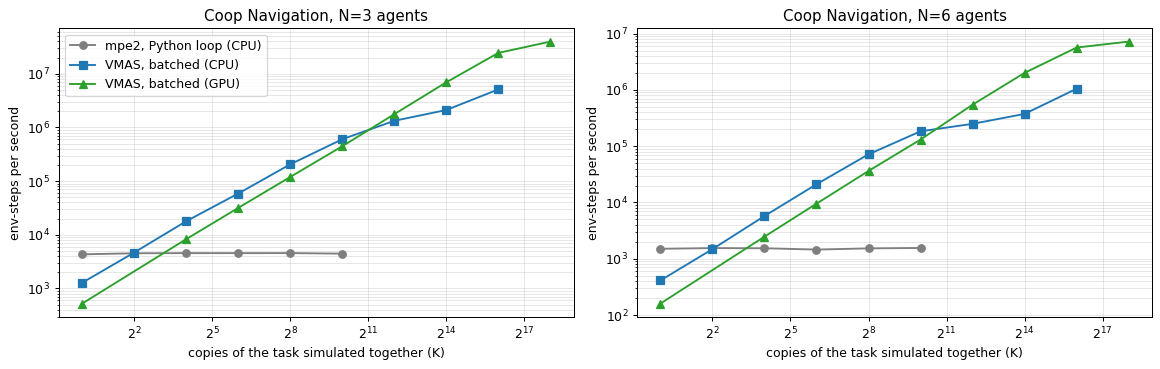

In [3]:
rows = load_throughput()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
plot_throughput(rows, 3, ax[0]); plot_throughput(rows, 6, ax[1])
ax[0].legend()
plt.tight_layout()
best = {(r["backend"], r["device"], r["N"]): max(x["env_steps_per_s"] for x in rows
        if (x["backend"], x["device"], x["N"]) == (r["backend"], r["device"], r["N"])) for r in rows}
for N in (3, 6):
    print(f"N={N}: loop {best[('loop', 'cpu', N)]:>10,.0f}   VMAS CPU {best[('vmas', 'cpu', N)]:>12,.0f}   "
          f"VMAS GPU {best.get(('vmas', 'cuda', N), float('nan')):>12,.0f}  env-steps/s (best K)")

* The **loop is flat**: more copies, same speed. With 6 agents it is ~3x slower than with 3 (more agents to loop over).
* **VMAS gets faster with more copies**, by orders of magnitude.
* With few copies the **GPU is slower than the CPU**: launching GPU work has a fixed cost per step. It only pays off with thousands of copies.

Throughput is not the goal, though. Can the learning algorithm *use* all that experience?

## 3. The same MAPPO, the same 10 minutes

The MAPPO from notebook 04 (one shared actor and critic, centralised critic) trained four ways, each for **10 minutes of training time**
(time spent on evaluation and videos is not counted), evaluated every 30 seconds:

| run | simulator | copies per update | device |
|---|---|---|---|
| mpe2 loop | `mpe2`, Python loop | 64 | CPU |
| VMAS CPU 64 | VMAS | 64 | CPU |
| VMAS CPU 1024 | VMAS | 1024 | CPU |
| VMAS GPU 4096 | VMAS | 4096 | GPU |

With thousands of copies, one update sees a huge batch; we keep the **minibatch size** fixed (6,400 time steps), so bigger batches mean more gradient steps per update.

*Caveat:* VMAS's port follows the same rules as `mpe2`'s Coop Navigation but not the same physics, and its reward is scaled differently.
We compare the behaviour metric both report the same way - **landmark distance**: for each landmark, the distance to the closest agent, averaged (0 = every landmark covered).

time to reach landmark distance 0.05:
  mpe2 loop, CPU, 64 copies      not reached   |    1.8M steps in 10 min
  VMAS, CPU, 64 copies           7.5 min (   6.0M steps)   |    7.9M steps in 10 min
  VMAS, CPU, 1024 copies         4.0 min (   8.2M steps)   |   20.8M steps in 10 min
  VMAS, GPU, 4096 copies         1.0 min (  10.6M steps)   |  102.4M steps in 10 min


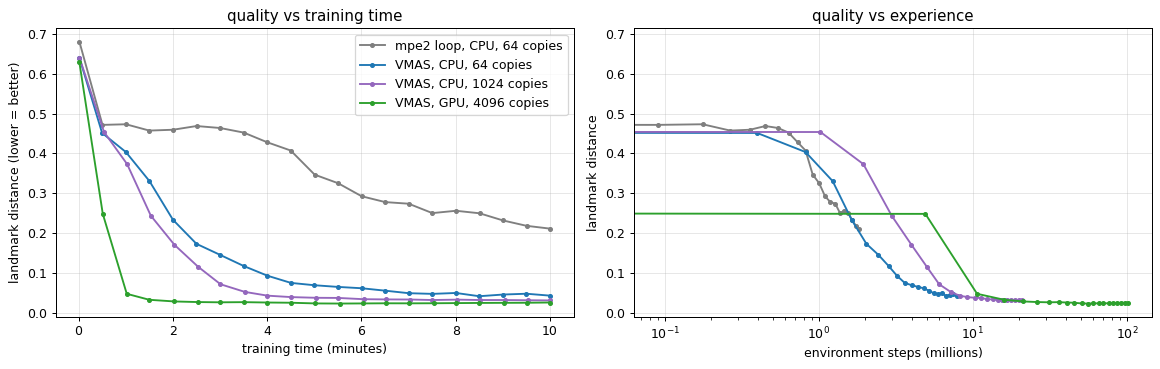

In [4]:
runs3 = wallclock_runs(3)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
plot_vs_time(runs3, ax=ax[0], x="train_time", title="quality vs training time", ylabel="landmark distance (lower = better)")
plot_vs_time(runs3, ax=ax[1], x="step", title="quality vs experience", ylabel="landmark distance")
ax[1].set_xscale("log"); ax[0].legend()
plt.tight_layout()
print("time to reach landmark distance 0.05:")
for name, run in runs3.items():
    r = reached(run, threshold=0.05)
    steps = run["log"]["step"][-1]
    print(f"  {RUN_STYLE[name.replace('N3', 'N{N}')][0]:<28} " + (f"{r[0]:5.1f} min ({r[1] / 1e6:6.1f}M steps)" if r else "  not reached")
          + f"   | {steps / 1e6:6.1f}M steps in 10 min")

Left: per **minute**, the GPU run is far ahead - it gets the agents onto the landmarks in about a minute, the 64-copy CPU run needs ~7 minutes.
Right: per **environment step** it is *behind* - it needs more experience for the same quality, because huge batches use each sample less
(fewer updates per sample). Vectorization trades sample efficiency for throughput, and when simulation is cheap that is a very good trade.

(The `mpe2` loop curve is for reference only: a different implementation of the task, so its numbers are not directly comparable.)

In [5]:
show_video(vmas_video(runs3["vmas_spread_N3_gpu4096"], title="MAPPO, VMAS GPU, 10 min of training"), fps=15)

## 4. Back to the 6-agent wall

Notebook 04: 6 agents, `mpe2` loop, 8M steps, 2.9 hours - and the agents still huddled in the middle.
Here: 6 agents on VMAS, **30 minutes** each, CPU with 64 copies vs GPU with 4096 copies.

VMAS, CPU, 64 copies         11.1M steps in 30.0 min  -> landmark distance 0.325, coverage 0.08
VMAS, GPU, 4096 copies      178.6M steps in 30.0 min  -> landmark distance 0.125, coverage 0.55


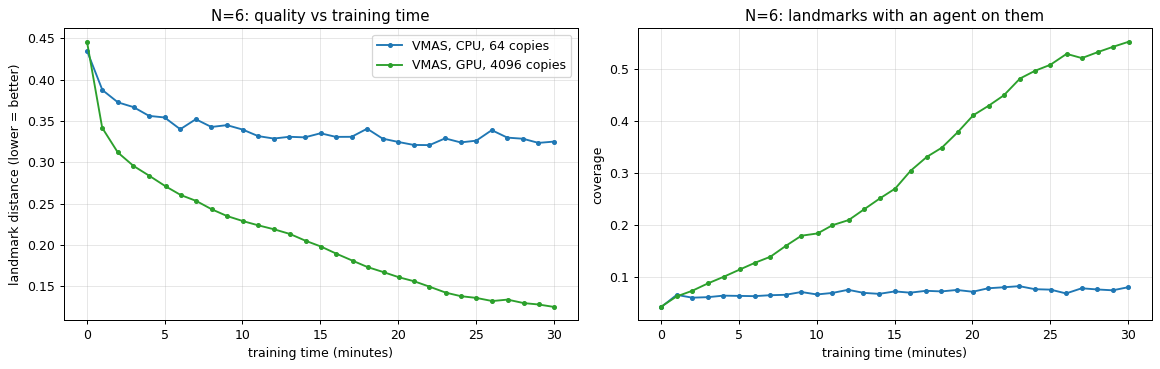

In [6]:
runs6 = wallclock_runs(6)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
plot_vs_time(runs6, ax=ax[0], x="train_time", N=6, title="N=6: quality vs training time", ylabel="landmark distance (lower = better)")
plot_vs_time(runs6, "coverage", ax=ax[1], x="train_time", N=6, title="N=6: landmarks with an agent on them", ylabel="coverage")
ax[0].legend()
plt.tight_layout()
for name, run in runs6.items():
    log = run["log"]
    print(f"{RUN_STYLE[name.replace('N6', 'N{N}')][0]:<26} {log['step'][-1] / 1e6:6.1f}M steps in {log['train_time'][-1] / 60:4.1f} min"
          f"  -> landmark distance {log['landmark_dist'][-1]:.3f}, coverage {log['coverage'][-1]:.2f}")

In [7]:
show_video(vmas_video(runs6["vmas_spread_N6_cpu64"], title="6 agents, VMAS CPU, 30 min")
           + vmas_video(runs6["vmas_spread_N6_gpu4096"], title="6 agents, VMAS GPU, 30 min"), fps=15)

**With enough experience, the wall starts to break.**
* The CPU run (~11M steps in 30 minutes) stays stuck: the agents bunch up in the middle and cover hardly any landmark - the same huddle as notebook 04.
* The GPU run (~180M steps in the same 30 minutes) keeps improving: the agents learn to spread out and claim landmarks, and the curve is
  still going down when the time runs out.
* So for 6 agents, a large part of the problem was simply **not enough experience** to discover how to split up the landmarks - and that is
  exactly what vectorization provides. It is still not solved: who-goes-where is a coordination / credit-assignment problem
  (notebooks 03b and 06), and more agents need even more experience.

## Takeaways
* **Vectorization** = simulate many copies of the task as one batch of tensor operations instead of a loop. VMAS does this for whole
  multi-agent physics worlds, on CPU or GPU.
* The payoff is **experience per second** - orders of magnitude more than a Python loop - which turns hours of MARL training into minutes
  (3 agents: ~1 minute on the GPU vs ~7 minutes on the CPU with 64 copies).
* It is not free: **huge batches learn less per sample** (tune the minibatch size), and the **GPU only wins with many copies**.
* **Experience can break a wall**: with 6 agents, the CPU run stayed stuck in a huddle while the GPU run - 16x more experience in the same
  30 minutes - learned to spread out.
* It needs a simulator written for it: a ported task (VMAS's Coop Navigation) is not identical to the original (`mpe2`).
* Next: instead of more experience, **think ahead** - lookahead search and AlphaZero.